
### 1. Tokenization
Splitting text into <span style="color:#16A34A">words or sentences</span>.



In [1]:
import nltk
from nltk.tokenize import word_tokenize


text = "I love Natural Language Processing        !!!"

tokens = word_tokenize(text)

print(tokens)

['I', 'love', 'Natural', 'Language', 'Processing', '!', '!', '!']



### 2. Text Normalization
Converting text into a <span style="color:#16A34A">consistent format</span>.


In [2]:
import re

text = "HELLO!!!   NLP 2026"

text = text.lower()
text = re.sub(r"[^a-z0-9\s]", "", text)
text = re.sub(r"\s+", " ", text).strip()

print(text)

hello nlp 2026



### 3. Stopwords Removal
Removing <span style="color:#16A34A">common, less meaningful words</span>.


In [3]:
import nltk
from nltk.corpus import stopwords


text = "I am learning the Natural Language Processing"

tokens = text.lower().split()

stop_words = set(stopwords.words("english"))

filtered = [
    word for word in tokens
    if word not in stop_words
]

print(filtered)

['learning', 'natural', 'language', 'processing']



### 4. Stemming
Reducing words to their <span style="color:#16A34A">root forms</span>.


In [4]:
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer
stemmer = PorterStemmer()

words = ["playing", "played", "studies", "running"]

for word in words:
    print(word, "→", stemmer.stem(word))
    
print("="*50)

lemmatizer = WordNetLemmatizer()
for word in words:
    print(word, "→", lemmatizer.lemmatize(word, pos="v"))

playing → play
played → play
studies → studi
running → run
playing → play
played → play
studies → study
running → run



### 5. Lemmatization
Converting words into their <span style="color:#16A34A">dictionary base forms</span>.


In [5]:
import nltk
from nltk.stem import WordNetLemmatizer


lemmatizer = WordNetLemmatizer()

words = ["running", "mice", "cars", "better"]

for word in words:
    print(word, "→", lemmatizer.lemmatize(word))    # محددتش يعتبرها اسم 

running → running
mice → mouse
cars → car
better → better


In [6]:
lemmatizer.lemmatize("running", pos="v")     # حددت و قولت النوع انه فعل

'run'

### 6. Regular Expressions (Regex)
Finding and manipulating <span style="color:#16A34A">text patterns</span>.


In [7]:
import re

text = """
Contact us:
alaa@gmail.com
support@example.com
"""

emails = re.findall(
    r"[\w.-]+@[\w.-]+\.\w+",
    text
)

print(emails)

['alaa@gmail.com', 'support@example.com']


In [8]:
text = "Hello!!! NLP 2026 @ AI"

cleaned = re.sub(
    r"[^a-zA-Z0-9\s]",
    "",
    text
)

print(cleaned)

Hello NLP 2026  AI


### 7. Text Representation
Converting text into <span style="color:#16A34A">numerical features</span>.

### 7.1 Bag of Words (BoW)
Representing text using <span style="color:#16A34A">word frequencies</span>.


In [9]:
from sklearn.feature_extraction.text import CountVectorizer
documents = [
"I love AI and AI",
"I love Python",
"I love AI Python"
]
vectorizer = CountVectorizer()   # default ngram=1
X = vectorizer.fit_transform(documents)
print(vectorizer.get_feature_names_out())
print(X.toarray())   # BOW

['ai' 'and' 'love' 'python']
[[2 1 1 0]
 [0 0 1 1]
 [1 0 1 1]]



### 7.2 N-grams
Representing <span style="color:#16A34A">sequences of consecutive words</span>.


In [10]:
from sklearn.feature_extraction.text import CountVectorizer

text = ["I love ML and AI and Python",
        "I love Python",
        "I love AI Python"
       ]

vectorizer = CountVectorizer(ngram_range=(1, 3))  # uni,bi,tri

X = vectorizer.fit_transform(text)

print(vectorizer.get_feature_names_out())   # Vocabulary ---> ngram
print(X.toarray())

['ai' 'ai and' 'ai and python' 'ai python' 'and' 'and ai' 'and ai and'
 'and python' 'love' 'love ai' 'love ai python' 'love ml' 'love ml and'
 'love python' 'ml' 'ml and' 'ml and ai' 'python']
[[1 1 1 0 2 1 1 1 1 0 0 1 1 0 1 1 1 1]
 [0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 1]
 [1 0 0 1 0 0 0 0 1 1 1 0 0 0 0 0 0 1]]


### 7.3 TF-IDF
Measuring <span style="color:#16A34A">word importance</span> across documents.



# TF-IDF Mathematical Calculations

## 1. Mathematical Formulas

### Term Frequency (TF)

$$
TF(t,d)=\frac{f(t,d)}{Total\ Words(d)}
$$

حيث:

- $f(t,d)$: عدد مرات تكرار الكلمة داخل المستند.
- $Total\ Words(d)$: إجمالي عدد الكلمات في المستند.

### Inverse Document Frequency (IDF)

$$
IDF(t)=\log\left(\frac{N}{DF(t)}\right)
$$

حيث:

- $N$: إجمالي عدد المستندات.
- $DF(t)$: عدد المستندات التي ظهرت فيها الكلمة مرة واحدة على الأقل.

### TF-IDF

$$
TFIDF(t,d)=TF(t,d)\times IDF(t)
$$

### L2 Normalization

$$
TFIDF_{norm}(t,d)=
\frac{TFIDF(t,d)}
{\sqrt{\sum_{j=1}^{n}TFIDF(t_j,d)^2}}
$$

---

## 2. Scikit-learn Implementation

The `TfidfVectorizer` uses the following default formulas:

**Raw Term Frequency:**

$$
TF(t,d)=f(t,d)
$$

**Smoothed IDF:**

$$
IDF(t)=\ln\left(\frac{N+1}{DF(t)+1}\right)+1
$$

**TF-IDF:**

$$
TFIDF(t,d)=TF(t,d)\times IDF(t)
$$

**Note:** The following calculations use Scikit-learn's actual formulas.

---

## 3. Document 1

**Document:** I love machine learning

$$
N=3
$$

### Feature: learning

$$
TF(learning,D_1)=1
$$

$$
IDF(learning)=\ln\left(\frac{4}{4}\right)+1=1
$$

$$
TFIDF=1\times1=1
$$

### Feature: love

$$
TF(love,D_1)=1
$$

$$
IDF(love)=\ln\left(\frac{4}{3}\right)+1=1.288
$$

$$
TFIDF=1\times1.288=1.288
$$

### Feature: love machine

$$
TF(love\ machine,D_1)=1
$$

$$
IDF(love\ machine)=\ln\left(\frac{4}{2}\right)+1=1.693
$$

$$
TFIDF=1\times1.693=1.693
$$

### Feature: machine

$$
TF(machine,D_1)=1
$$

$$
IDF(machine)=\ln\left(\frac{4}{3}\right)+1=1.288
$$

$$
TFIDF=1\times1.288=1.288
$$

### Feature: machine learning

$$
TF(machine\ learning,D_1)=1
$$

$$
IDF(machine\ learning)=\ln\left(\frac{4}{3}\right)+1=1.288
$$

$$
TFIDF=1\times1.288=1.288
$$

### L2 Normalization

$$
L_2=\sqrt{
1^2+1.288^2+1.693^2+1.288^2+1.288^2
}
$$

$$
L_2\approx2.973
$$

### Final Values

$$
learning=\frac{1}{2.973}\approx0.34
$$

$$
love=\frac{1.288}{2.973}\approx0.43
$$

$$
love\ machine=\frac{1.693}{2.973}\approx0.57
$$

$$
machine=\frac{1.288}{2.973}\approx0.43
$$

$$
machine\ learning=\frac{1.288}{2.973}\approx0.43
$$

---

## 4. Document 2

**Document:** I love deep learning

### Feature: deep

$$
TF(deep,D_2)=1
$$

$$
IDF(deep)=\ln\left(\frac{4}{2}\right)+1=1.693
$$

$$
TFIDF=1\times1.693=1.693
$$

### Feature: deep learning

$$
TF(deep\ learning,D_2)=1
$$

$$
IDF(deep\ learning)=\ln\left(\frac{4}{2}\right)+1=1.693
$$

$$
TFIDF=1\times1.693=1.693
$$

### Feature: learning

$$
TF(learning,D_2)=1
$$

$$
IDF(learning)=\ln\left(\frac{4}{4}\right)+1=1
$$

$$
TFIDF=1\times1=1
$$

### Feature: love

$$
TF(love,D_2)=1
$$

$$
IDF(love)=\ln\left(\frac{4}{3}\right)+1=1.288
$$

$$
TFIDF=1\times1.288=1.288
$$

### Feature: love deep

$$
TF(love\ deep,D_2)=1
$$

$$
IDF(love\ deep)=\ln\left(\frac{4}{2}\right)+1=1.693
$$

$$
TFIDF=1\times1.693=1.693
$$

### L2 Normalization

$$
L_2=\sqrt{
1.693^2+1.693^2+1^2+1.288^2+1.693^2
}
$$

$$
L_2\approx3.355
$$

### Final Values

$$
deep=\frac{1.693}{3.355}\approx0.50
$$

$$
deep\ learning=\frac{1.693}{3.355}\approx0.50
$$

$$
learning=\frac{1}{3.355}\approx0.30
$$

$$
love=\frac{1.288}{3.355}\approx0.38
$$

$$
love\ deep=\frac{1.693}{3.355}\approx0.50
$$

---

## 5. Document 3

**Document:** machine learning is useful

### Feature: is

$$
TF(is,D_3)=1
$$

$$
IDF(is)=\ln\left(\frac{4}{2}\right)+1=1.693
$$

$$
TFIDF=1\times1.693=1.693
$$

### Feature: is useful

$$
TF(is\ useful,D_3)=1
$$

$$
IDF(is\ useful)=\ln\left(\frac{4}{2}\right)+1=1.693
$$

$$
TFIDF=1\times1.693=1.693
$$

### Feature: learning

$$
TF(learning,D_3)=1
$$

$$
IDF(learning)=\ln\left(\frac{4}{4}\right)+1=1
$$

$$
TFIDF=1\times1=1
$$

### Feature: learning is

$$
TF(learning\ is,D_3)=1
$$

$$
IDF(learning\ is)=\ln\left(\frac{4}{2}\right)+1=1.693
$$

$$
TFIDF=1\times1.693=1.693
$$

### Feature: machine

$$
TF(machine,D_3)=1
$$

$$
IDF(machine)=\ln\left(\frac{4}{3}\right)+1=1.288
$$

$$
TFIDF=1\times1.288=1.288
$$

### Feature: machine learning

$$
TF(machine\ learning,D_3)=1
$$

$$
IDF(machine\ learning)=\ln\left(\frac{4}{3}\right)+1=1.288
$$

$$
TFIDF=1\times1.288=1.288
$$

### Feature: useful

$$
TF(useful,D_3)=1
$$

$$
IDF(useful)=\ln\left(\frac{4}{2}\right)+1=1.693
$$

$$
TFIDF=1\times1.693=1.693
$$

### L2 Normalization

$$
L_2=\sqrt{
1.693^2+1.693^2+1^2+1.693^2+
1.288^2+1.288^2+1.693^2
}
$$

$$
L_2\approx3.973
$$

### Final Values

$$
is=\frac{1.693}{3.973}\approx0.43
$$

$$
is\ useful=\frac{1.693}{3.973}\approx0.43
$$

$$
learning=\frac{1}{3.973}\approx0.25
$$

$$
learning\ is=\frac{1.693}{3.973}\approx0.43
$$

$$
machine=\frac{1.288}{3.973}\approx0.32
$$

$$
machine\ learning=\frac{1.288}{3.973}\approx0.32
$$

$$
useful=\frac{1.693}{3.973}\approx0.43
$$

---

## 6. Final TF-IDF Matrix

$$
X=
\begin{bmatrix}
0&0&0&0&0.34&0&0.43&0&0.57&0.43&0.43&0\\
0.50&0.50&0&0&0.30&0&0.38&0.50&0&0&0&0\\
0&0&0.43&0.43&0.25&0.43&0&0&0&0.32&0.32&0.43
\end{bmatrix}
$$

**Matrix Shape:**

$$
X\in\mathbb{R}^{3\times12}
$$

**Conclusion:**

Each document is converted into a numerical vector. Each value represents the normalized TF-IDF weight of a word or a two-word phrase (Bigram). Zero indicates that the feature does not appear in that document.


In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
documents = [
"I love machine learning",
"I love deep learning",
"machine learning is useful"
]
vectorizer = TfidfVectorizer(ngram_range=(1, 2))

X = vectorizer.fit_transform(documents)

print(vectorizer.get_feature_names_out())
print(X.toarray().round(2))

['deep' 'deep learning' 'is' 'is useful' 'learning' 'learning is' 'love'
 'love deep' 'love machine' 'machine' 'machine learning' 'useful']
[[0.   0.   0.   0.   0.34 0.   0.43 0.   0.57 0.43 0.43 0.  ]
 [0.5  0.5  0.   0.   0.3  0.   0.38 0.5  0.   0.   0.   0.  ]
 [0.   0.   0.43 0.43 0.25 0.43 0.   0.   0.   0.32 0.32 0.43]]


In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
texts = [
    "I love this product",
    "Amazing experience",
    "I hate this product",
    "Very bad experience"
]
labels = [1, 1, 0, 0]
vectorizer = TfidfVectorizer(ngram_range=(1, 2))
X = vectorizer.fit_transform(texts)
print(vectorizer.get_feature_names_out())
print(X.toarray().round(2))
print("="*50)
model = LogisticRegression()

model.fit(X, labels)
new_text = ["I love this experience","I Hate this experience"]
new_vector = vectorizer.transform(new_text)
print(model.predict(new_vector))

['amazing' 'amazing experience' 'bad' 'bad experience' 'experience' 'hate'
 'hate this' 'love' 'love this' 'product' 'this' 'this product' 'very'
 'very bad']
[[0.   0.   0.   0.   0.   0.   0.   0.51 0.51 0.4  0.4  0.4  0.   0.  ]
 [0.62 0.62 0.   0.   0.49 0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.51 0.51 0.   0.   0.4  0.4  0.4  0.   0.  ]
 [0.   0.   0.47 0.47 0.37 0.   0.   0.   0.   0.   0.   0.   0.47 0.47]]
[1 0]


In [31]:
from sklearn.naive_bayes import MultinomialNB
texts = [
    "I love this product",
    "Amazing quality",
    "I hate this product",
    "Very bad quality"
]
labels = ["Positive", "Positive", "Negative", "Negative"]
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(texts)
print(vectorizer.get_feature_names_out())
print(X.toarray().round(2))
print("="*50)

model = MultinomialNB()
model.fit(X, labels)
test = vectorizer.transform(["Amazing product","Bad product"])
print(model.predict(test))

['amazing' 'bad' 'hate' 'love' 'product' 'quality' 'this' 'very']
[[0.   0.   0.   0.67 0.53 0.   0.53 0.  ]
 [0.79 0.   0.   0.   0.   0.62 0.   0.  ]
 [0.   0.   0.67 0.   0.53 0.   0.53 0.  ]
 [0.   0.62 0.   0.   0.   0.49 0.   0.62]]
['Positive' 'Negative']


In [32]:
from sklearn.naive_bayes import MultinomialNB
messages = [
"Win free money now",
"Claim your prize",
"Let's meet tomorrow",
"Send me the project report"
]
labels = ["Spam", "Spam", "Ham", "Ham"]
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(messages)
model = MultinomialNB()
model.fit(X, labels)
new_message = ["Win a free prize","Let's meet now"]
X_new = vectorizer.transform(new_message)
print(model.predict(X_new))

['Spam' 'Ham']


In [37]:

from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

text = "love AI AI"

# 1. One-Hot Encoding
words = text.split()
onehot = OneHotEncoder(sparse_output=False)
print("One-Hot Encoding:")
print(onehot.fit_transform([[w] for w in words]))
print(onehot.get_feature_names_out())

# 2. Bag of Words
bow = CountVectorizer()
print("\nBag of Words:")
print(bow.fit_transform([text]).toarray())
print(bow.get_feature_names_out())

# 3. TF-IDF
tfidf = TfidfVectorizer()
print("\nTF-IDF:")
print(tfidf.fit_transform([text]).toarray().round(3))
print(tfidf.get_feature_names_out())


One-Hot Encoding:
[[0. 1.]
 [1. 0.]
 [1. 0.]]
['x0_AI' 'x0_love']

Bag of Words:
[[2 1]]
['ai' 'love']

TF-IDF:
[[0.894 0.447]]
['ai' 'love']


### 8. Word Embeddings
Representing words as <span style="color:#16A34A">dense numerical vectors</span>.


### 8.1 Word2Vec – Google
Learning word vectors from <span style="color:#16A34A">surrounding context</span>.


In [53]:
from gensim.models import Word2Vec

sentences = [
    # Royal family
    ["king", "queen", "royal", "crown", "palace", "kingdom"],
    ["king", "queen", "royal", "throne", "palace", "kingdom"],
    ["king", "prince", "royal", "crown", "kingdom"],
    ["queen", "princess", "royal", "crown", "kingdom"],
    ["king", "queen", "prince", "princess", "royal"],

    # Human relationships
    ["man", "woman", "person", "human", "people"],
    ["man", "woman", "human", "person", "adult"],
    ["boy", "girl", "child", "kid", "young"],
    ["man", "boy", "male", "father", "son"],
    ["woman", "girl", "female", "mother", "daughter"],

    # Fruits
    ["apple", "banana", "orange", "mango", "fruit"],
    ["apple", "banana", "fruit", "food", "healthy"],
    ["orange", "mango", "fruit", "vitamin", "healthy"],
    ["apple", "orange", "banana", "fruit", "fresh"],
    ["mango", "banana", "fruit", "sweet", "food"],

    # Vehicles
    ["car", "bus", "truck", "vehicle", "transport"],
    ["car", "truck", "vehicle", "road", "drive"],
    ["bus", "car", "vehicle", "transport", "road"],
    ["truck", "bus", "vehicle", "transport", "drive"],
    ["car", "bus", "truck", "road", "transport"],

    # Programming
    ["python", "java", "programming", "coding", "software"],
    ["python", "programming", "code", "developer", "software"],
    ["java", "python", "coding", "developer", "programming"],
    ["python", "java", "software", "programming", "developer"],
    ["coding", "programming", "software", "code", "developer"],
]

# Repeat the corpus to provide more training examples
sentences = sentences * 30

model = Word2Vec(
    sentences=sentences,
    vector_size=50,
    window=3,
    min_count=1,
    workers=1,
    sg=0,
    epochs=100,
    seed=42
)

# Similarity testing
pairs = [
    ("king", "queen"),
    ("king", "prince"),
    ("apple", "banana"),
    ("car", "truck"),
    ("python", "java"),
    ("man", "woman"),
    ("car", "man"),
    ("apple", "truck")
]

for word1, word2 in pairs:
    similarity = model.wv.similarity(word1, word2)
    print(f"{word1:10} - {word2:10}: {similarity:.4f}")

king       - queen     : 0.9172
king       - prince    : 0.8889
apple      - banana    : 0.8763
car        - truck     : 0.9626
python     - java      : 0.9217
man        - woman     : 0.6203
car        - man       : 0.3586
apple      - truck     : 0.3718


### 8.1.1 CBOW (Continuous Bag of Words)
Predicting a <span style="color:#16A34A">target word</span> from surrounding words.

###  8.1.2 Skip-gram
Predicting <span style="color:#16A34A">surrounding words</span> from a target word.


In [54]:
from gensim.models import Word2Vec

sentences = [
    ["machine", "learning", "is", "great"],
    ["machine", "learning", "uses", "data"],
    ["machine", "learning", "builds", "models"],
    ["deep", "learning", "uses", "neural", "networks"],
    ["deep", "learning", "builds", "neural", "models"],
    ["natural", "language", "processing", "is", "AI"],
    ["natural", "language", "processing", "uses", "machine", "learning"],
    ["AI", "uses", "machine", "learning"],
    ["AI", "uses", "deep", "learning"],
    ["neural", "networks", "are", "used", "in", "deep", "learning"],
] * 50

# CBOW
cbow = Word2Vec(
    sentences,
    vector_size=50,
    window=3,
    min_count=1,
    sg=0,
    workers=1,
    epochs=100,
    seed=42
)

# Skip-gram
skipgram = Word2Vec(
    sentences,
    vector_size=50,
    window=3,
    min_count=1,
    sg=1,
    workers=1,
    epochs=100,
    seed=42
)

# Compare Similarity
print("CBOW:", cbow.wv.similarity("machine", "learning"))
print("Skip-gram:", skipgram.wv.similarity("machine", "learning"))

# Compare vectors
print("\nCBOW Vector:\n", cbow.wv["learning"])
print("\nSkip-gram Vector:\n", skipgram.wv["learning"])

CBOW: 0.65055674
Skip-gram: 0.608228

CBOW Vector:
 [-1.1830337e-01  2.1820202e-01  4.5174081e-02 -1.2065156e-01
  1.7181619e-01  1.5881841e-01 -2.4457109e-01  7.5533316e-02
 -2.2480057e-01 -1.8927498e-01  1.9246243e-01  2.8787562e-01
  1.5352575e-01  2.3839273e-01  2.5217292e-01  3.1154069e-01
 -1.1041465e-01 -5.0359958e-01  4.0434446e-02  2.0816658e-02
 -2.8576730e-02 -1.5622072e-01 -3.2583356e-01  3.0986378e-01
  3.5128853e-01 -5.8657736e-02  6.4146273e-02  6.3428335e-02
  3.8313703e-04 -1.3486122e-01 -8.8683426e-02 -1.2586294e-01
 -3.9724302e-01  3.3616029e-02  1.6040398e-01 -1.3760424e-01
  9.9399328e-02 -3.0819487e-03 -9.5105506e-02  1.9627333e-01
  2.1594968e-01  1.4663197e-01  2.5395083e-01 -1.0362786e-01
 -2.8783198e-02  1.6647036e-01 -7.2255969e-02  2.1962199e-01
  1.7463368e-01 -1.3909391e-01]

Skip-gram Vector:
 [-0.13904412  0.18774435  0.13188243 -0.13338526  0.1478988   0.24053515
 -0.27759364  0.13709436 -0.25058404 -0.18539032  0.22940673  0.29932553
  0.21959934  0.27

In [55]:

from gensim.models import Word2Vec

sentences = [
    ["machine", "learning", "is", "great"],
    ["machine", "learning", "uses", "data"],
    ["machine", "learning", "builds", "models"],
    ["deep", "learning", "uses", "neural", "networks"],
    ["deep", "learning", "builds", "neural", "models"],
    ["natural", "language", "processing", "is", "AI"],
    ["natural", "language", "processing", "uses", "machine", "learning"],
    ["AI", "uses", "machine", "learning"],
    ["AI", "uses", "deep", "learning"],
    ["neural", "networks", "are", "used", "in", "deep", "learning"],
] * 50

# Train CBOW
cbow = Word2Vec(
    sentences,
    vector_size=50,
    window=3,
    min_count=1,
    sg=0, # CBOW
    workers=1,
    epochs=100,
    seed=42
)

# Train Skip-gram
skipgram = Word2Vec(
    sentences,
    vector_size=50,
    window=3,
    min_count=1,
    sg=1, # Skip-gram
    workers=1,
    epochs=100,
    seed=42
)

# Compare Similarity
pairs = [
    ("machine", "learning"),
    ("deep", "learning"),
    ("machine", "AI"),
    ("neural", "networks"),
    ("python", "learning")  # Not in vocabulary
]

for w1, w2 in pairs:
    if w1 in cbow.wv and w2 in cbow.wv:
        print(f"\n{w1} - {w2}")
        print(f"CBOW:      {cbow.wv.similarity(w1, w2):.4f}")
        print(f"Skip-gram: {skipgram.wv.similarity(w1, w2):.4f}")
    else:
        print(f"\n{w1} - {w2}: Word not in vocabulary")

# Most Similar Words
for word in ["machine", "learning", "AI"]:
    print(f"\nMost Similar to '{word}'")

    print("CBOW:", cbow.wv.most_similar(word, topn=5))
    print("Skip-gram:", skipgram.wv.most_similar(word, topn=5))

# Compare Word Vectors
print("\nCBOW Vector:")
print(cbow.wv["learning"])

print("\nSkip-gram Vector:")
print(skipgram.wv["learning"])

# Vector Dimensions
print("\nCBOW Shape:", cbow.wv["learning"].shape)
print("Skip-gram Shape:", skipgram.wv["learning"].shape)



machine - learning
CBOW:      0.6506
Skip-gram: 0.6082

deep - learning
CBOW:      0.6031
Skip-gram: 0.6091

machine - AI
CBOW:      0.8552
Skip-gram: 0.8200

neural - networks
CBOW:      0.8985
Skip-gram: 0.8592

python - learning: Word not in vocabulary

Most Similar to 'machine'
CBOW: [('data', 0.8963835835456848), ('is', 0.8897204995155334), ('AI', 0.8552133440971375), ('great', 0.8508048057556152), ('language', 0.8379325270652771)]
Skip-gram: [('data', 0.8906962871551514), ('is', 0.8836917877197266), ('great', 0.8233730792999268), ('AI', 0.8199707865715027), ('language', 0.7976641654968262)]

Most Similar to 'learning'
CBOW: [('data', 0.8056002855300903), ('builds', 0.6604902148246765), ('machine', 0.6505566835403442), ('models', 0.6458472013473511), ('neural', 0.6149768829345703)]
Skip-gram: [('data', 0.7084187865257263), ('models', 0.6725631952285767), ('builds', 0.651273787021637), ('deep', 0.6091122627258301), ('machine', 0.6082280874252319)]

Most Similar to 'AI'
CBOW: [('pr

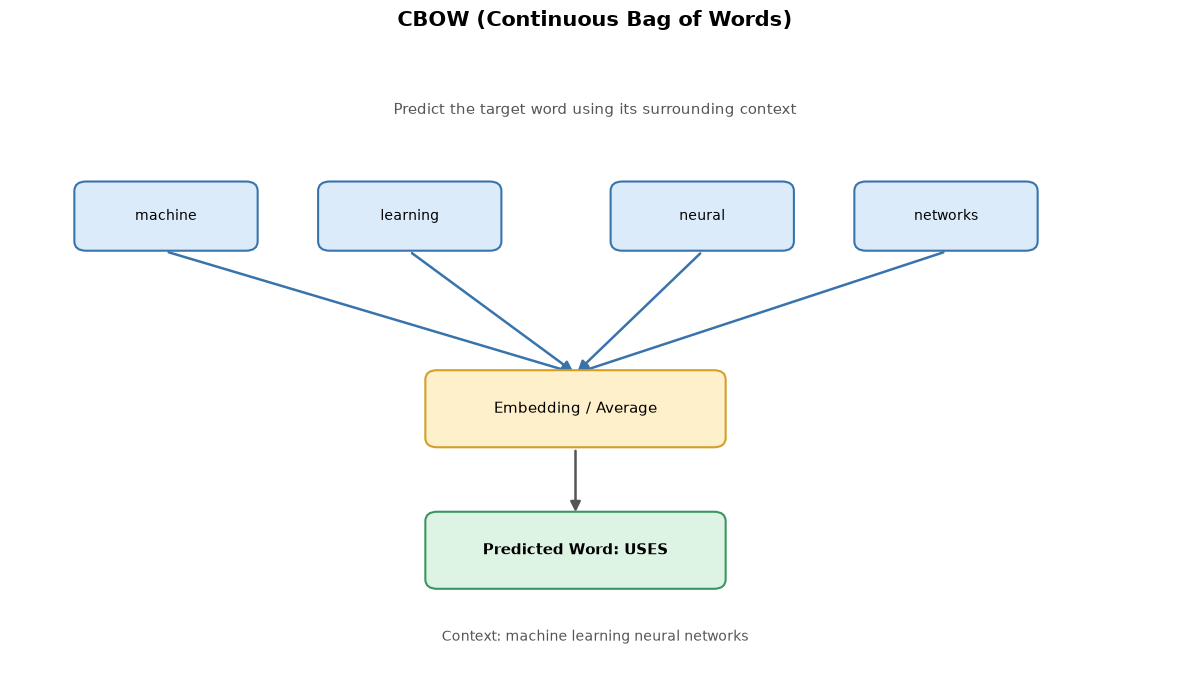

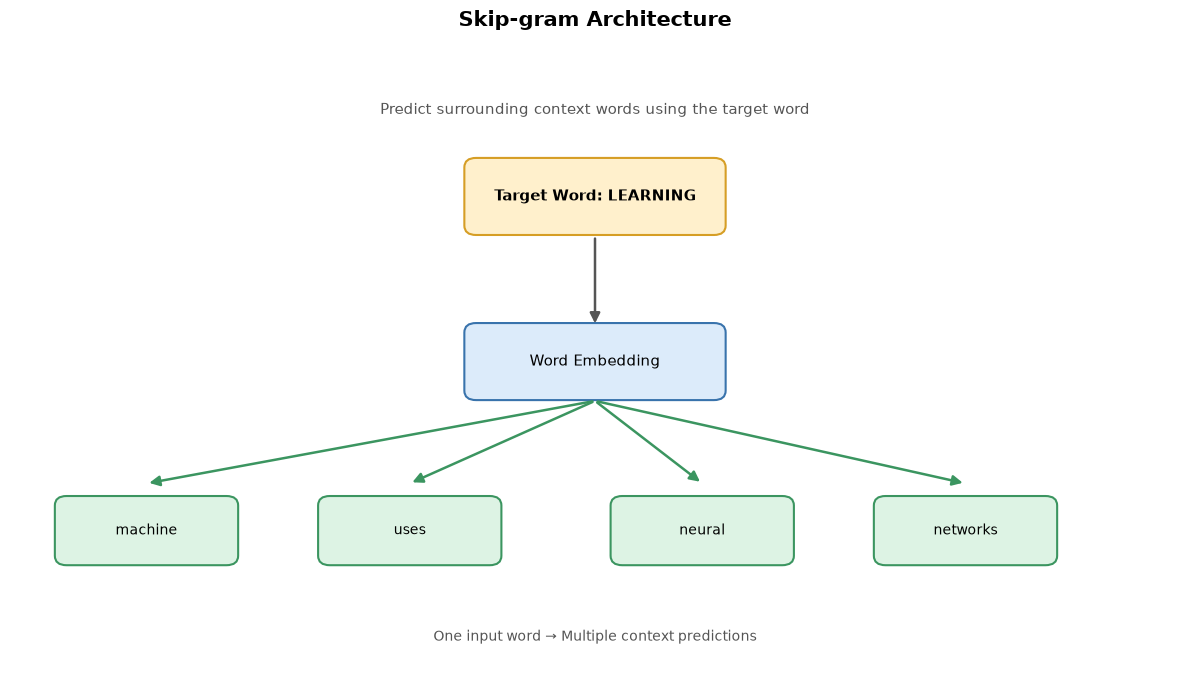

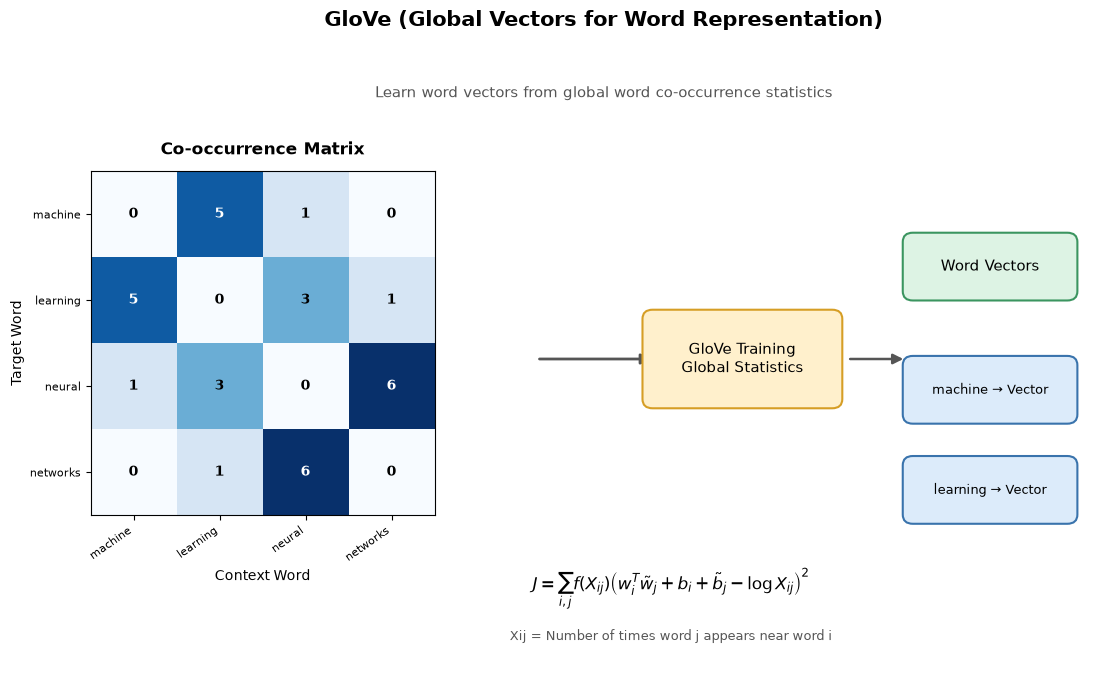

In [67]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import numpy as np

# ==========================================
# General Drawing Functions
# ==========================================

def draw_box(ax, x, y, w, h, text,
             color="#DCEBFA", edge="#3973AC",
             fontsize=10, weight="normal"):

    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.04,rounding_size=0.12",
        linewidth=1.5,
        edgecolor=edge,
        facecolor=color
    )

    ax.add_patch(box)

    ax.text(
        x + w / 2,
        y + h / 2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
        weight=weight,
        wrap=True
    )


def draw_arrow(ax, start, end, color="#555555",
               width=1.8, style="-|>", connection="arc3"):

    arrow = FancyArrowPatch(
        start,
        end,
        arrowstyle=style,
        mutation_scale=15,
        linewidth=width,
        color=color,
        connectionstyle=connection
    )

    ax.add_patch(arrow)


def setup_ax(ax, title):
    ax.set_title(title, fontsize=15, weight="bold", pad=18)
    ax.set_xlim(0, 12)
    ax.set_ylim(0, 8)
    ax.axis("off")


# ==========================================
# 1. CBOW Architecture
# ==========================================

def draw_cbow():

    fig, ax = plt.subplots(figsize=(12, 7))
    setup_ax(ax, "CBOW (Continuous Bag of Words)")

    ax.text(
        6, 7.2,
        "Predict the target word using its surrounding context",
        ha="center", fontsize=11, color="#555555"
    )

    # Context words
    context_words = [
        ("machine", 0.7),
        ("learning", 3.2),
        ("neural", 6.2),
        ("networks", 8.7)
    ]

    for word, x in context_words:
        draw_box(
            ax, x, 5.5, 1.8, 0.8, word,
            color="#DCEBFA"
        )

        draw_arrow(
            ax, (x + 0.9, 5.45), (5.8, 3.9),
            color="#3973AC"
        )

    # Hidden layer
    draw_box(
        ax, 4.3, 3.0, 3.0, 0.9,
        "Embedding / Average",
        color="#FFF0CC",
        edge="#D69E25",
        fontsize=11
    )

    draw_arrow(ax, (5.8, 2.95), (5.8, 2.1))

    # Output
    draw_box(
        ax, 4.3, 1.2, 3.0, 0.9,
        "Predicted Word: USES",
        color="#DDF3E4",
        edge="#3B9560",
        fontsize=11,
        weight="bold"
    )

    ax.text(
        6, 0.5,
        "Context: machine learning neural networks",
        ha="center", fontsize=10, color="#555555"
    )

    plt.tight_layout()
    plt.show()


# ==========================================
# 2. Skip-gram Architecture
# ==========================================

def draw_skipgram():

    fig, ax = plt.subplots(figsize=(12, 7))
    setup_ax(ax, "Skip-gram Architecture")

    ax.text(
        6, 7.2,
        "Predict surrounding context words using the target word",
        ha="center", fontsize=11, color="#555555"
    )

    # Input word
    draw_box(
        ax, 4.7, 5.7, 2.6, 0.9,
        "Target Word: LEARNING",
        color="#FFF0CC",
        edge="#D69E25",
        fontsize=11,
        weight="bold"
    )

    # Hidden layer
    draw_arrow(ax, (6, 5.65), (6, 4.5))

    draw_box(
        ax, 4.7, 3.6, 2.6, 0.9,
        "Word Embedding",
        color="#DCEBFA",
        edge="#3973AC",
        fontsize=11
    )

    # Context predictions
    outputs = [
        ("machine", 0.5),
        ("uses", 3.2),
        ("neural", 6.2),
        ("networks", 8.9)
    ]

    for word, x in outputs:

        draw_arrow(
            ax, (6, 3.55), (x + 0.9, 2.5),
            color="#3B9560"
        )

        draw_box(
            ax, x, 1.5, 1.8, 0.8,
            word,
            color="#DDF3E4",
            edge="#3B9560"
        )

    ax.text(
        6, 0.5,
        "One input word → Multiple context predictions",
        ha="center", fontsize=10, color="#555555"
    )

    plt.tight_layout()
    plt.show()


# ==========================================
# 3. GloVe Architecture
# ==========================================

def draw_glove():

    fig, ax = plt.subplots(figsize=(13, 8))
    setup_ax(ax, "GloVe (Global Vectors for Word Representation)")

    ax.text(
        6, 7.4,
        "Learn word vectors from global word co-occurrence statistics",
        ha="center", fontsize=11, color="#555555"
    )

    # Co-occurrence matrix
    words = ["machine", "learning", "neural", "networks"]

    matrix = np.array([
        [0, 5, 1, 0],
        [5, 0, 3, 1],
        [1, 3, 0, 6],
        [0, 1, 6, 0]
    ])

    ax_matrix = fig.add_axes([0.07, 0.30, 0.36, 0.43])

    ax_matrix.imshow(matrix, cmap="Blues")

    ax_matrix.set_xticks(range(len(words)))
    ax_matrix.set_yticks(range(len(words)))

    ax_matrix.set_xticklabels(words, rotation=35, ha="right", fontsize=8)
    ax_matrix.set_yticklabels(words, fontsize=8)

    ax_matrix.set_title(
        "Co-occurrence Matrix",
        fontsize=12,
        weight="bold",
        pad=12
    )

    # Show matrix values
    for i in range(len(words)):
        for j in range(len(words)):
            value = matrix[i, j]

            ax_matrix.text(
                j, i, str(value),
                ha="center",
                va="center",
                color="white" if value >= 4 else "black",
                fontsize=10,
                weight="bold"
            )

    ax_matrix.set_xlabel("Context Word")
    ax_matrix.set_ylabel("Target Word")

    # Arrow to training
    draw_arrow(
        ax, (5.2, 4.0), (6.6, 4.0),
        color="#555555",
        width=2
    )

    # Training box
    draw_box(
        ax, 6.5, 3.4, 2.3, 1.2,
        "GloVe Training\nGlobal Statistics",
        color="#FFF0CC",
        edge="#D69E25",
        fontsize=11
    )

    # Arrow to output
    draw_arrow(
        ax, (8.9, 4.0), (9.6, 4.0),
        color="#555555"
    )

    # Output vectors
    draw_box(
        ax, 9.6, 4.8, 2.0, 0.8,
        "Word Vectors",
        color="#DDF3E4",
        edge="#3B9560",
        fontsize=11
    )

    draw_box(
        ax, 9.6, 3.2, 2.0, 0.8,
        "machine → Vector",
        color="#DCEBFA",
        edge="#3973AC",
        fontsize=9
    )

    draw_box(
        ax, 9.6, 1.9, 2.0, 0.8,
        "learning → Vector",
        color="#DCEBFA",
        edge="#3973AC",
        fontsize=9
    )

    # Objective function
    ax.text(
        6.8, 1.0,
        r"$J = \sum_{i,j} f(X_{ij})"
        r"\left(w_i^T \tilde{w}_j + b_i + \tilde{b}_j"
        r" - \log X_{ij}\right)^2$",
        fontsize=12,
        ha="center"
    )

    ax.text(
        6.8, 0.35,
        "Xij = Number of times word j appears near word i",
        fontsize=9,
        ha="center",
        color="#555555"
    )

    plt.show()


# ==========================================
# Run All Diagrams
# ==========================================

draw_cbow()
draw_skipgram()
draw_glove()


### 8.2 GloVe (Global Vectors) – Stanford University
Learning word vectors using <span style="color:#16A34A">global co-occurrence statistics</span>.


In [68]:

import numpy as np
from gensim.models import Word2Vec
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity

corpus = [
    "machine learning uses data to learn patterns",
    "deep learning uses neural networks",
    "neural networks learn complex patterns",
    "artificial intelligence uses machine learning",
    "natural language processing understands human language",
    "word2vec learns words from surrounding context",
    "glove learns from global word cooccurrence statistics",
    "machine learning and deep learning are AI techniques",
    "python is used for artificial intelligence",
    "computers learn language using neural networks"
] * 20

tokens = [s.split() for s in corpus]

# 1. Word2Vec CBOW
cbow = Word2Vec(tokens, vector_size=50, window=3,
                min_count=1, sg=0, epochs=100)

# 2. Word2Vec Skip-gram
skipgram = Word2Vec(tokens, vector_size=50, window=3,
                    min_count=1, sg=1, epochs=100)

# 3. GloVe (educational approximation)
vocab = sorted(set(w for s in tokens for w in s))
word_id = {w: i for i, w in enumerate(vocab)}

matrix = np.zeros((len(vocab), len(vocab)))

for sentence in tokens:
    for i, word in enumerate(sentence):
        for j in range(max(0, i-3), min(len(sentence), i+4)):
            if i != j:
                matrix[word_id[word], word_id[sentence[j]]] += 1

glove = TruncatedSVD(n_components=10, random_state=42)
glove_vectors = glove.fit_transform(np.log1p(matrix))

# Compare similar words
word = "learning"

print("CBOW:", cbow.wv.most_similar(word, topn=5))
print("Skip-gram:", skipgram.wv.most_similar(word, topn=5))

similarities = cosine_similarity(
    glove_vectors[word_id[word]].reshape(1, -1),
    glove_vectors
)[0]

indices = similarities.argsort()[::-1][1:6]

print("GloVe:", [(vocab[i], round(similarities[i], 3))
                for i in indices])


CBOW: [('deep', 0.9865031242370605), ('machine', 0.9806498289108276), ('and', 0.9774205088615417), ('are', 0.9703636169433594), ('techniques', 0.9693276286125183)]
Skip-gram: [('machine', 0.9775578379631042), ('deep', 0.9717981219291687), ('and', 0.9462061524391174), ('AI', 0.9357665181159973), ('techniques', 0.9329142570495605)]
GloVe: [('deep', np.float64(0.824)), ('machine', np.float64(0.801)), ('are', np.float64(0.797)), ('uses', np.float64(0.773)), ('and', np.float64(0.708))]


### 8.3 FastText – Meta AI
Learning word vectors using <span style="color:#16A34A">character-level N-grams</span>.


In [69]:
from gensim.models import FastText
sentences = [
    ["playing", "football", "today"],
    ["played", "football", "yesterday"],
    ["player", "likes", "football"],
    ["machine", "learning", "is", "useful"]
]
model = FastText(
    sentences,
    vector_size=100,
    window=5,
    min_count=1,
    sg=1,
    min_n=3,
    max_n=6
)
print(model.wv["playing"])
print(model.wv.most_similar("playing"))

[-3.0492785e-04  1.3500341e-03 -8.1695447e-04  2.5932884e-04
  1.1289353e-03  1.6023819e-03 -6.8767450e-04 -8.1523071e-04
  1.6094607e-04 -6.7666208e-04 -1.3948157e-03  6.6343817e-04
 -1.6886207e-04  1.6636222e-03  1.2009385e-03  1.9423112e-03
  3.0698077e-04  6.8215327e-04  1.2222504e-03 -5.8352819e-04
 -5.3157174e-04 -7.0984272e-04  1.1941831e-03 -8.8154210e-04
  1.1050818e-04 -9.3097173e-05  8.2386471e-04  1.2910591e-03
  9.4839005e-04 -2.3519723e-03 -1.4314211e-04 -3.9668816e-05
  2.2868323e-03  5.0767011e-04  9.6587806e-05  1.1279552e-03
  1.7677806e-03  1.8538554e-03 -2.7206051e-04  1.7548370e-03
 -1.2912360e-03 -2.1005164e-04 -1.5183692e-03 -1.9586771e-03
 -1.2239643e-03 -9.1725180e-04  8.3012634e-04 -1.8172935e-03
  7.2050648e-04  5.0202513e-04 -1.1562220e-03  4.2448845e-04
  6.9634506e-04  5.2782620e-04  1.9114772e-04 -8.4887224e-04
 -1.3242094e-03 -1.2986496e-03 -7.2304939e-04 -6.7780347e-04
 -2.3658782e-04 -6.5403915e-04 -1.0969987e-03  6.3308231e-05
 -1.1380638e-03 -5.44680

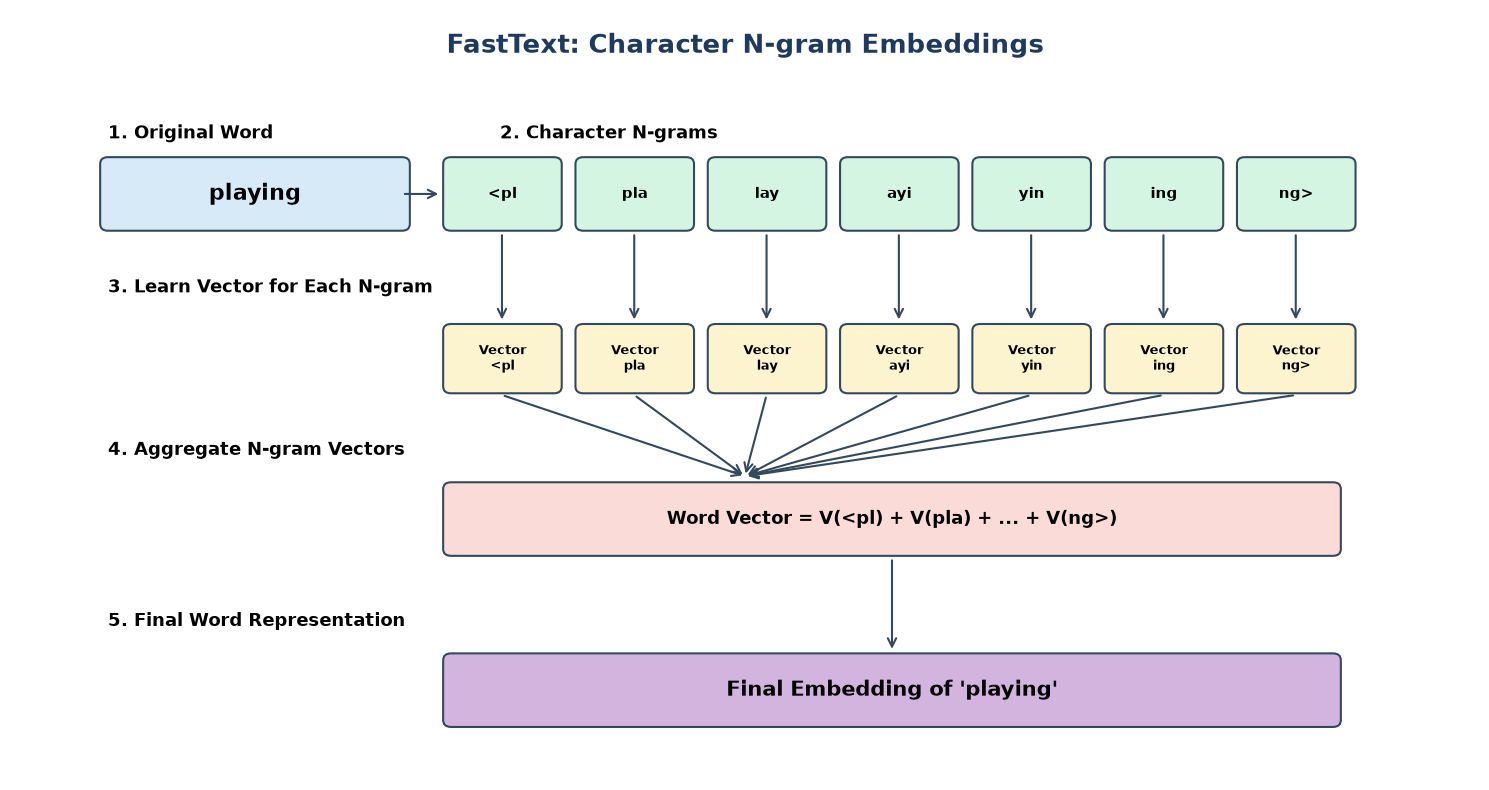

In [72]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# ============================
# FastText Character N-grams
# ============================

word = "<playing>"

ngrams = [
    "<pl", "pla", "lay", "ayi",
    "yin", "ing", "ng>"
]

fig, ax = plt.subplots(figsize=(15, 8))

ax.set_xlim(0, 15)
ax.set_ylim(0, 9)
ax.axis("off")

# Drawing function
def draw_box(x, y, w, h, text, color, size=11):
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.08",
        facecolor=color,
        edgecolor="#34495E",
        linewidth=1.5
    )
    ax.add_patch(box)

    ax.text(
        x + w/2, y + h/2,
        text,
        ha="center",
        va="center",
        fontsize=size,
        fontweight="bold"
    )


def arrow(x1, y1, x2, y2):
    ax.add_patch(
        FancyArrowPatch(
            (x1, y1), (x2, y2),
            arrowstyle="->",
            mutation_scale=15,
            linewidth=1.5,
            color="#34495E"
        )
    )


# Title
ax.text(
    7.5, 8.5,
    "FastText: Character N-gram Embeddings",
    ha="center",
    fontsize=19,
    fontweight="bold",
    color="#1F3A5F"
)

# Step 1
ax.text(1, 7.5, "1. Original Word",
        fontsize=13, fontweight="bold")

draw_box(1, 6.5, 3, 0.7, "playing", "#D6EAF8", 16)

# Step 2
ax.text(5, 7.5, "2. Character N-grams",
        fontsize=13, fontweight="bold")

for i, gram in enumerate(ngrams):
    x = 4.5 + i * 1.35
    draw_box(x, 6.5, 1.05, 0.7, gram, "#D5F5E3", 11)

arrow(4, 6.85, 4.4, 6.85)

# Step 3
ax.text(1, 5.7, "3. Learn Vector for Each N-gram",
        fontsize=13, fontweight="bold")

for i, gram in enumerate(ngrams):
    x = 4.5 + i * 1.35

    draw_box(x, 4.6, 1.05, 0.65,
             f"Vector\n{gram}", "#FCF3CF", 9)

    arrow(x + 0.52, 6.4, x + 0.52, 5.35)

# Step 4
ax.text(1, 3.8, "4. Aggregate N-gram Vectors",
        fontsize=13, fontweight="bold")

draw_box(
    4.5, 2.7, 9, 0.7,
    "Word Vector = V(<pl) + V(pla) + ... + V(ng>)",
    "#FADBD8", 13
)

for i in range(len(ngrams)):
    x = 5.02 + i * 1.35
    arrow(x, 4.5, 7.5, 3.55)

# Step 5
ax.text(1, 1.8, "5. Final Word Representation",
        fontsize=13, fontweight="bold")

draw_box(
    4.5, 0.7, 9, 0.7,
    "Final Embedding of 'playing'",
    "#D2B4DE", 15
)

arrow(9, 2.6, 9, 1.5)

plt.tight_layout()
plt.show()

In [71]:

from gensim.models import FastText

# 1. Training Data
sentences = [
    ["playing", "football", "today"],
    ["played", "football", "yesterday"],
    ["player", "likes", "football"],
    ["players", "enjoy", "playing"],
    ["play", "football", "with", "friends"],
    ["machine", "learning", "is", "useful"]
]

# 2. Train FastText
model = FastText(
    sentences,
    vector_size=100,
    window=3,
    min_count=1,
    sg=1,
    min_n=3,
    max_n=6,
    epochs=100,
    workers=1,
    seed=42
)

# 3. Word Vector
print("Vector:", model.wv["playing"][:10])

# 4. Most Similar Words
print("\nSimilar Words:")
print(model.wv.most_similar("playing", topn=5))

# 5. Character N-grams
print("\nCharacter N-grams:")
print(model.wv.get_vecattr("playing", "count"))

# 6. Similarity
print("\nSimilarity:")
print(model.wv.similarity("playing", "played"))

# 7. Out-of-Vocabulary (OOV)
new_word = "playful"

print("\nOOV Word:", new_word)
print("In Vocabulary:", new_word in model.wv.key_to_index)
print("Generated Vector:", model.wv[new_word][:10])


Vector: [ 3.6791866e-04  1.0683287e-03 -4.4621239e-04  6.7539548e-04
  5.2080426e-04 -1.6983401e-03  1.2523469e-03  5.2579049e-05
 -3.4902513e-04  5.9729402e-05]

Similar Words:
[('played', 0.44321680068969727), ('play', 0.4425378739833832), ('player', 0.4312918186187744), ('players', 0.26915085315704346), ('yesterday', 0.22462941706180573)]

Character N-grams:
2

Similarity:
0.4432168

OOV Word: playful
In Vocabulary: False
Generated Vector: [ 1.93765573e-03  2.34920206e-03 -4.30519809e-04  1.01189755e-04
  6.49549766e-04 -7.47081140e-05 -8.40500172e-04 -1.44875620e-03
 -7.64373457e-04 -2.16652825e-03]


In [73]:

from gensim.models import Word2Vec
sentences = [
    ["king", "man", "queen", "woman"],
    ["paris", "france", "cairo", "egypt"],
    ["man", "king", "royal"],
    ["woman", "queen", "royal"]
]
model = Word2Vec(
    sentences,
    vector_size=100,
    window=5,
    min_count=1,
    sg=1
)
result = model.wv.most_similar(
    positive=["king", "woman"],
    negative=["man"],
    topn=3
)
print(result)


[('queen', 0.09298086166381836), ('royal', 0.042461100965738297), ('egypt', 0.00974996853619814)]


In [85]:
# import sys

# !{sys.executable} -m pip install spacy
# !{sys.executable} -m spacy download en_core_web_sm

### 9. Named Entity Recognition (NER)
Identifying <span style="color:#16A34A">entities</span> such as people, organizations, and locations.


In [82]:

import spacy

nlp = spacy.load("en_core_web_sm")

text = "Alaa joined Google in January 2024 and lives in Egypt."

doc = nlp(text)

print("Named Entities:\n")

for ent in doc.ents:
    print(f"{ent.text:20} {ent.label_}")

print("=" * 65)

# Display IOB tags and entity types
print(f"{'Token':<12} {'IOB':<8} {'Entity Type'}")
print("-" * 35)

for token in doc:
    print(f"{token.text:<12} {token.ent_iob_:<8} {token.ent_type_ or '-'}")


Named Entities:

Alaa                 PERSON
Google               ORG
January 2024         DATE
Egypt                GPE
Token        IOB      Entity Type
-----------------------------------
Alaa         B        PERSON
joined       O        -
Google       B        ORG
in           O        -
January      B        DATE
2024         I        DATE
and          O        -
lives        O        -
in           O        -
Egypt        B        GPE
.            O        -


In [84]:

import spacy
import pandas as pd

# Load model
nlp = spacy.load("en_core_web_sm")

# Input text
text = "Alaa joined Google in January 2024 and lives in Egypt."
doc = nlp(text)

# 1. Named Entities
print("Named Entities:")
for ent in doc.ents:
    print(f"{ent.text:<20} {ent.label_}")

# 2. IOB Tagging
print("\nIOB Tagging:")

data = [
    {
        "Token": token.text,
        "IOB": token.ent_iob_,
        "Entity": token.ent_type_ or "-"
    }
    for token in doc
]

df = pd.DataFrame(data)
print(df.to_string(index=False))


Named Entities:
Alaa                 PERSON
Google               ORG
January 2024         DATE
Egypt                GPE

IOB Tagging:
  Token IOB Entity
   Alaa   B PERSON
 joined   O      -
 Google   B    ORG
     in   O      -
January   B   DATE
   2024   I   DATE
    and   O      -
  lives   O      -
     in   O      -
  Egypt   B    GPE
      .   O      -


In [81]:

import spacy

nlp = spacy.load("en_core_web_sm")

text = "Alaa loves Artificial Intelligence and builds smart systems."

doc = nlp(text)

print("POS Tagging:\n")

for token in doc:
    print(f"{token.text:20} {token.pos_:10} {token.tag_}")


POS Tagging:

Alaa                 PROPN      NNP
loves                VERB       VBZ
Artificial           PROPN      NNP
Intelligence         PROPN      NNP
and                  CCONJ      CC
builds               VERB       VBZ
smart                ADJ        JJ
systems              NOUN       NNS
.                    PUNCT      .
